# 07 — Tide risk (`EXP-H05`)

## 1. Objective
Test whether entry-time Tide risk constraints improve the left tail of the frozen H4 parent without retaining less than 80% of its mean after-cost return.

## 2. Hypothesis
A causal 97.5% ES budget plus the inherited 1× margin cap reduces realised ES at 5, 15, and 60 minutes while preserving at least 80% of the parent mean return.

## 3. Null
No registered Tide budget policy passes the all-horizon ES and mean-return conjunction after Holm correction across the policy family.

## 4. Information set
BTCUSDT one-minute OHLC known at each decision close. The H4 development result supplies the frozen parent rule. Tide may only reduce or refuse entry exposure.

## 5. Dataset
`btcusdt-1m`, bound to the same frozen manifest as H4.

## 6. Data quality
The standard minute-bar audit applies. Missing volatility estimates, ES binds, margin binds, liquidation proxies, and failed origins are counted.

## 7. Labels
Risk is positive loss. Historical ES uses the worst 2.5% of training horizon returns. Economic outcomes are after-cost one-minute returns on the parent decision clock.

## 8. Baseline
The unconstrained H4 decision stream is the nested control. Signals, volatility-targeted base size, costs, horizons, and splits are identical in every arm.

## 9. Model family
The registered ladder is static, volatility-scaled, and stress-scaled budgets. Each policy applies `min(1, B_t / estimated_es)` and cannot increase exposure.

## 10. Splits
24-month train, 6-month validation, 6-month step, and final 12-month untouched test.

## 11. Configuration
The source of truth is `research.protocol.H5_CONFIG`. Development may use frozen exploratory H4; sealed H5 confirmation requires H4 to be sealed and retained.

In [1]:
import os
import sys
from dataclasses import asdict
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

root = Path.cwd().resolve()
while root != root.parent and not (root / "research" / "__init__.py").exists():
    root = root.parent
if not (root / "research" / "__init__.py").exists():
    raise RuntimeError("open this notebook from the trading repository")
os.chdir(root)
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
os.environ.setdefault("AWS_PROFILE", "trading")
os.environ.setdefault("AWS_DEFAULT_REGION", "ap-southeast-2")
os.environ.setdefault("DATA_STORE", "s3")
os.environ.setdefault("S3_BUCKET", "trading-data-centheos")
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", "{:.6g}".format)

from research.registry import config_digest, load_record
from research.report import (
    confirmation_blockers,
    plot_tide_constraint_activity,
    plot_tide_es_tradeoff,
    quality_table,
    record_development_decision,
    tide_risk_summary,
)

## 5–6. Dataset and data quality

Reload and verify the frozen single-series manifest. Collector rows appended after the freeze are counted and excluded.

In [2]:
from research.evaluate import align_to_frozen_dataset
from research.load import load_research_bars
from research.manifest import load_manifest
from research.protocol import H5_CONFIG

MANIFEST_PATH = root / "research" / "registry" / "datasets" / "btcusdt-1m.json"
manifest = load_manifest(MANIFEST_PATH)
loaded_bars, objects = load_research_bars(
    venue=H5_CONFIG["venue"],
    symbol=H5_CONFIG["symbol"],
    timeframe=H5_CONFIG["timeframe"],
    bucket=H5_CONFIG["bucket"],
    profile=H5_CONFIG["profile"],
    region=H5_CONFIG["region"],
)
bars, quality, collector_rows_after_freeze = align_to_frozen_dataset(
    loaded_bars, manifest, objects
)
print("dataset_id:", manifest.dataset_id)
print("dataset_digest:", manifest.digest)
print("frozen_window:", manifest.start, "to", manifest.end)
print("collector_rows_after_freeze:", collector_rows_after_freeze)
display(quality_table({H5_CONFIG["symbol"]: quality}))

Excluded 4189 collector rows after frozen end 2026-10-17T10:43:00+00:00; ohlcv/binance/BTCUSDT/1m/2026.parquet etag b67bbf4dddd1bcb2658bac4d361452ec -> ca4e9019202b9062abfdb9b434b6bedc, size 5482639 -> 5593177


dataset_id: btcusdt-1m
dataset_digest: c1192eca8fa673c386b4ff3aad751f4f2d4895e2b02d7b693a42aac1ecd28188
frozen_window: 2020-01-01T00:00:00+00:00 to 2026-10-17T10:43:00+00:00
collector_rows_after_freeze: 4189


,rows_in,rows_kept,duplicate_timestamps,off_grid_timestamps,nonpositive_prices,inconsistent_ohlc,missing_minutes,largest_gap_minutes
series,,,,,,,,
BTCUSDT,3573284,3573284,0,0,0,0,0,1


## 12–17. Evaluation

12. Statistical evaluation: exact paired sign tests for ES reduction, with Holm correction across the three budget policies.
13. Economic evaluation: mean after-cost return, Sharpe, turnover, and drawdown under the frozen H4 sizer and costs.
14. Calibration: realised 97.5% ES, budget utilisation, and zero constraint breaches.
15. Ablation: each budget policy versus the identical unconstrained H4 parent path.
16. Robustness: every registered rolling origin and declared horizon must be complete.
17. Failure analysis: failed origins, unavailable risk estimates, binds, and liquidation proxies remain visible.

In [3]:
from research.evaluate import evaluate_h5, h5_development_decision, h5_policy_comparison

CONFIG = H5_CONFIG
EXPERIMENT_ID = CONFIG["experiment_id"]
RECORD_PATH = root / "research" / "registry" / "EXP-H05.json"
H4_RECORD_PATH = root / "research" / "registry" / "EXP-H04.json"
record = load_record(RECORD_PATH)
h4_record = load_record(H4_RECORD_PATH)
evaluation = evaluate_h5(bars, h4_record, CONFIG)
if evaluation.sealed_access:
    raise RuntimeError("development notebook read the sealed test")
comparison = h5_policy_comparison(evaluation.risk_scores)
verdict = h5_development_decision(comparison, CONFIG).iloc[0]
risk_summary = tide_risk_summary(evaluation.risk_scores)
GATE_PARENT_RECORD = h4_record
GATE_OBJECTS = manifest.objects
print("config_digest:", config_digest(CONFIG))
print("parent_rule:", evaluation.parent_rule)
print("sealed_boundary:", evaluation.boundary)
print("development_null_decision:", verdict.null_decision)
print("working_policy:", verdict.benchmark)
print("failed_windows:", len(evaluation.failures))

H4 5m barrier labels exclusions: gaps=0 volatility=60 endpoints=5 stop_first_ties=3376
H4 15m barrier labels exclusions: gaps=0 volatility=60 endpoints=15 stop_first_ties=892
H4 60m barrier labels exclusions: gaps=0 volatility=60 endpoints=60 stop_first_ties=504
Excluded 1 close rows from one-minute baseline returns
H5 development has 1 unavailable one-minute returns
Excluded 1 close rows from one-minute baseline returns


config_digest: dee630c631ab1c41aa2ca392249fc3b99f7deb7572fbf344999c899786f3e7ac
parent_rule: first_passage_probability
sealed_boundary: 2025-10-17 00:00:00+00:00
development_null_decision: accept
working_policy: unconstrained_h4
failed_windows: 0


## How to read the scores

Realised ES is a positive loss magnitude, so lower is better. Mean-return non-inferiority requires each policy to preserve at least 80% of a positive parent mean; when the parent mean is negative, the policy must not make it more negative. Development selection also requires the Holm-adjusted policy-family p-value to be at most 5%.

In [4]:
display(comparison.sort_values(["horizon_minutes", "policy"]))
display(risk_summary)
if evaluation.failures:
    display(pd.DataFrame(evaluation.failures))

,horizon_minutes,policy,mean_parent_es,mean_policy_es,mean_es_reduction,median_es_reduction,mean_parent_return,mean_policy_return,mean_return_retention,mean_noninferiority,es_sign_pvalue,origins,expected_origins,holm_policy_pvalue
0,5,static_budget,0,0,0,0,0,0,NaN,True,1,7,7,1
6,5,stress_scaled_budget,0,0,0,0,0,0,NaN,True,1,7,7,1
3,5,volatility_scaled_budget,0,0,0,0,0,0,NaN,True,1,7,7,1
1,15,static_budget,0,0,0,0,0,0,NaN,True,1,7,7,1
7,15,stress_scaled_budget,0,0,0,0,0,0,NaN,True,1,7,7,1
4,15,volatility_scaled_budget,0,0,0,0,0,0,NaN,True,1,7,7,1
2,60,static_budget,2.79249e-08,2.79249e-08,0,0,-5.9457e-09,-5.9457e-09,NaN,True,1,7,7,1
8,60,stress_scaled_budget,2.79249e-08,2.79249e-08,0,0,-5.9457e-09,-5.9457e-09,NaN,True,1,7,7,1
5,60,volatility_scaled_budget,2.79249e-08,2.79249e-08,0,0,-5.9457e-09,-5.9457e-09,NaN,True,1,7,7,1


,horizon_minutes,policy,average_absolute_position,average_turnover,es_binds,liquidation_events,margin_binds,max_drawdown,mean_after_cost_return,median_budget_utilisation,realised_es,sharpe,total_simple_return,unavailable_risk_estimates
0,5,static_budget,0,0,0,0,0,0,0,0,0,0,0,0
1,5,stress_scaled_budget,0,0,0,0,0,0,0,0,0,0,0,0
2,5,unconstrained_h4,0,0,0,0,0,0,0,0,0,0,0,0
3,5,volatility_scaled_budget,0,0,0,0,0,0,0,0,0,0,0,0
4,15,static_budget,0,0,0,0,0,0,0,0,0,0,0,0
5,15,stress_scaled_budget,0,0,0,0,0,0,0,0,0,0,0,0
6,15,unconstrained_h4,0,0,0,0,0,0,0,0,0,0,0,0
7,15,volatility_scaled_budget,0,0,0,0,0,0,0,0,0,0,0,0
8,60,static_budget,0,0,0,0,0,0,0,0,0,0,0,0
9,60,stress_scaled_budget,0,0,0,0,0,0,0,0,0,0,0,0


## Development economic plots

The first panel shows the ES/mean-return trade-off. The second shows how often each constraint binds or fails closed because a point-in-time risk estimate is unavailable.

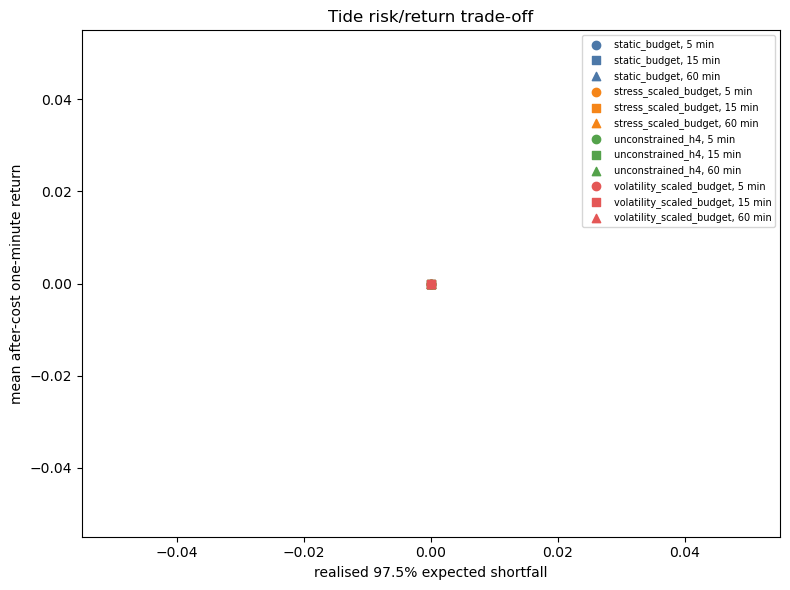

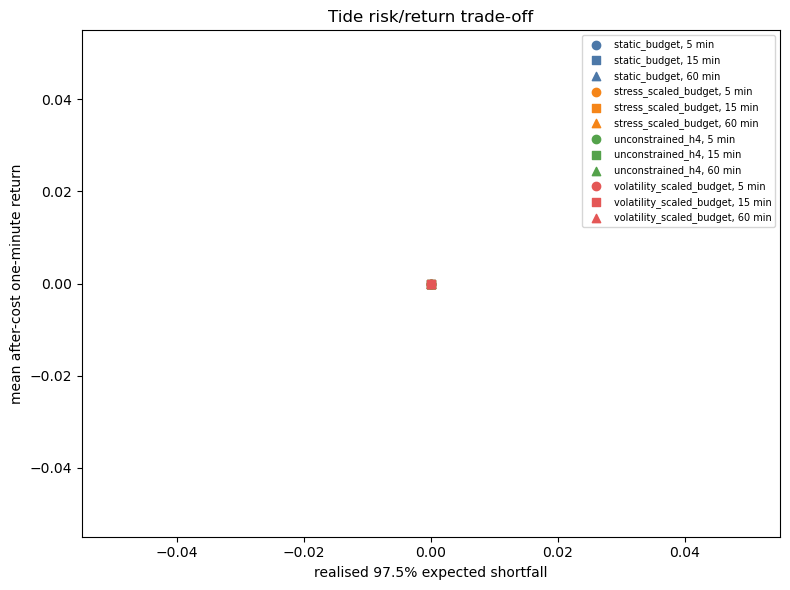

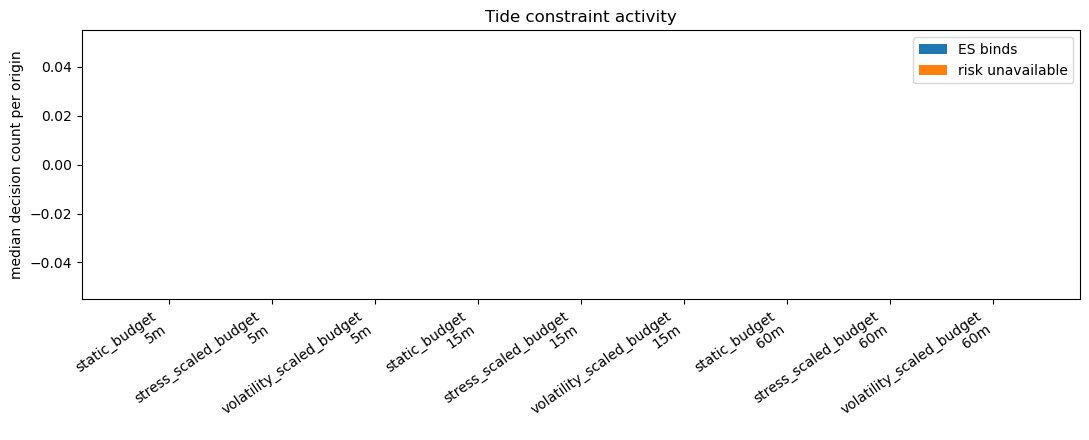

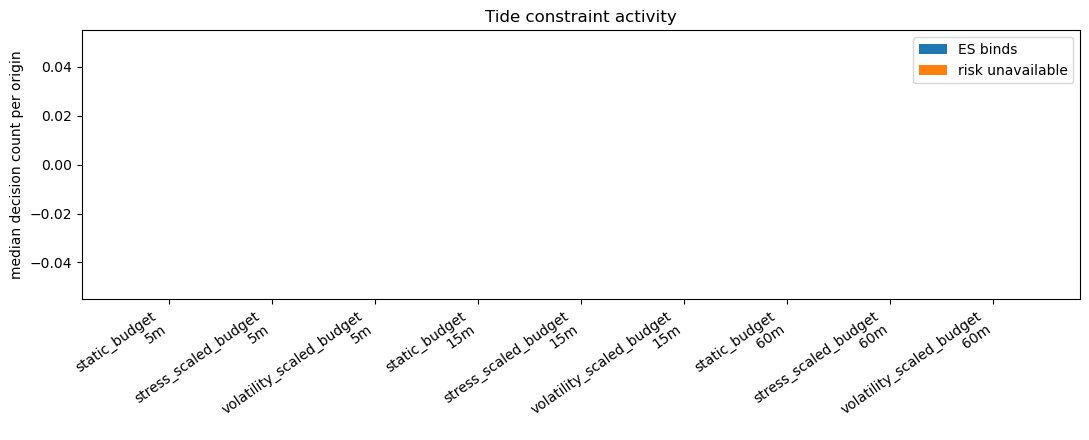

In [5]:
display(plot_tide_es_tradeoff(evaluation.risk_scores))
plt.show()
display(plot_tide_constraint_activity(evaluation.risk_scores))
plt.show()

## Risk calibration and adherence

Training ES and reference volatility are fitted separately at each origin using only labels available before validation. Constraint adherence must report zero post-authorisation budget breaches; unavailable estimates fail closed to zero exposure and remain counted.

In [6]:
if evaluation.diagnostics.empty:
    raise RuntimeError("H5 produced no risk diagnostics")
if int(evaluation.diagnostics["constraint_breaches"].sum()) != 0:
    raise RuntimeError("H5 produced a post-authorisation ES budget breach")
display(
    evaluation.diagnostics.groupby(["horizon_minutes", "policy"])[
        ["training_observations", "training_expected_shortfall", "training_reference_volatility", "constraint_breaches"]
    ].median().reset_index()
)

,horizon_minutes,policy,training_observations,training_expected_shortfall,training_reference_volatility,constraint_breaches
0,5,static_budget,1.0512e+06,0.00586843,0.000881881,0
1,5,stress_scaled_budget,1.0512e+06,0.00586843,0.000881881,0
2,5,volatility_scaled_budget,1.0512e+06,0.00586843,0.000881881,0
3,15,static_budget,1.05118e+06,0.0101847,0.000881881,0
4,15,stress_scaled_budget,1.05118e+06,0.0101847,0.000881881,0
5,15,volatility_scaled_budget,1.05118e+06,0.0101847,0.000881881,0
6,60,static_budget,1.05114e+06,0.0204385,0.000881881,0
7,60,stress_scaled_budget,1.05114e+06,0.0204385,0.000881881,0
8,60,volatility_scaled_budget,1.05114e+06,0.0204385,0.000881881,0


## Fitted Tide risk state

The table below isolates authorisation activity. H5 can reduce entry exposure but cannot add exposure, change the H4 direction, or re-authorise an open position.

In [7]:
activity_columns = [
    "horizon_minutes", "policy", "es_binds", "margin_binds",
    "unavailable_risk_estimates", "liquidation_events",
    "median_budget_utilisation", "average_absolute_position",
]
display(risk_summary[activity_columns])

,horizon_minutes,policy,es_binds,margin_binds,unavailable_risk_estimates,liquidation_events,median_budget_utilisation,average_absolute_position
0,5,static_budget,0,0,0,0,0,0
1,5,stress_scaled_budget,0,0,0,0,0,0
2,5,unconstrained_h4,0,0,0,0,0,0
3,5,volatility_scaled_budget,0,0,0,0,0,0
4,15,static_budget,0,0,0,0,0,0
5,15,stress_scaled_budget,0,0,0,0,0,0
6,15,unconstrained_h4,0,0,0,0,0,0
7,15,volatility_scaled_budget,0,0,0,0,0,0
8,60,static_budget,0,0,0,0,0,0
9,60,stress_scaled_budget,0,0,0,0,0,0


## 18. Result

This cell states the development answer only. It does not promote Tide or read the sealed year.

In [8]:
if verdict.null_decision == "reject":
    print(f"Answer: yes on development data; {verdict.benchmark} passes the registered gate.")
elif verdict.null_decision == "accept":
    print("Answer: no; keep unconstrained H4 as the working parent.")
else:
    print("Answer: not yet; failed origins make the evidence incomplete.")
print("Why:", verdict.reason)
print("This is development evidence. The sealed final year has not been read.")

Answer: no; keep unconstrained H4 as the working parent.
Why: no Tide budget lowers ES at every horizon while preserving the registered mean-return floor under Holm correction
This is development evidence. The sealed final year has not been read.


## 19. Decision

Record the development working policy without writing a sealed retain/reject decision. The registry is the lifecycle authority.

In [9]:
updated_record = record_development_decision(
    RECORD_PATH,
    verdict,
    experiment_id=EXPERIMENT_ID,
    dataset_id=manifest.dataset_id,
    dataset_digest=manifest.digest,
    config=CONFIG,
    root=root,
)
display(asdict(updated_record))
blockers = confirmation_blockers(
    root=root,
    record=updated_record,
    parent_record=GATE_PARENT_RECORD,
    dataset_objects=GATE_OBJECTS,
)
print("confirmation_blockers:")
for blocker in blockers:
    print("-", blocker)

Research code version is dirty: ad29123c1ddb52450245342d704ab33b3ec748e4+dirty


{'experiment_id': 'EXP-H05',
 'hypothesis': 'Entry-time ES, margin, and liquidation constraints improve left-tail outcomes without retaining less than 80% of unconstrained Wave mean after-cost return.',
 'null': 'No registered Tide budget policy reduces 97.5% realised ES at every horizon while retaining at least 80% of the parent mean after-cost return under the Holm-corrected policy family.',
 'parent_hypothesis': 'EXP-H04',
 'dataset_id': 'btcusdt-1m',
 'dataset_digest': 'c1192eca8fa673c386b4ff3aad751f4f2d4895e2b02d7b693a42aac1ecd28188',
 'code_version': 'ad29123c1ddb52450245342d704ab33b3ec748e4+dirty',
 'config_digest': 'dee630c631ab1c41aa2ca392249fc3b99f7deb7572fbf344999c899786f3e7ac',
 'status': 'Exploratory',
 'result': 'unconstrained_h4',
 'decision': '',
 'component': 'research.tide',
 'notebook': 'notebooks/research/07_tide_risk.ipynb',
 'horizons': (5, 15, 60),
 'sealed_access': False,
 'run_id': ''}

Research code version is dirty: ad29123c1ddb52450245342d704ab33b3ec748e4+dirty


confirmation_blockers:
- the research code is uncommitted (ad29123c1ddb52450245342d704ab33b3ec748e4+dirty)
- EXP-H04 has not been sealed and retained
- 1 stored object(s) have no immutable version id, for example ohlcv/binance/BTCUSDT/1m/2026.parquet


## Sealed confirmation

Leave disabled during development. Confirmation requires committed code, immutable dataset objects, the exact pre-registered digest, one development-selected budget policy, and sealed-retained H4.

In [ ]:
from research.evaluate import confirm_h5

RUN_SEALED_CONFIRMATION = False
if RUN_SEALED_CONFIRMATION:
    if blockers:
        raise RuntimeError("sealed confirmation is blocked: " + "; ".join(blockers))
    confirmation = confirm_h5(
        bars,
        updated_record,
        h4_record,
        dataset_manifest=manifest,
        root=root,
        record_path=RECORD_PATH,
        config=CONFIG,
    )
    display(asdict(confirmation.record))
else:
    print("sealed confirmation disabled")

## 20. Reusable implementation extracted

`research.tide` contains the causal ES calibration, static/volatility/stress budget paths, fail-closed entry authorisation, constraint counters, sign test, and Holm correction. `research.evaluate.evaluate_h5` and `confirm_h5` own walk-forward and sealed lifecycle handling.

## 21. Next experiment

H6 (`08_allocation`, `EXP-H06`) may compare a pre-registered opportunity/risk allocator only after one H5 budget is sealed and retained. The H5 budget remains fixed so H6 does not reopen risk-policy selection.